In [1]:
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

In [2]:
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
train_images = train_images.reshape((60000, 28, 28, 1)).astype("float32") / 255
test_images = test_images.reshape((10000, 28, 28, 1)).astype("float32") / 255

In [4]:
train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

In [5]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="rmsprop",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [6]:
history = model.fit(
    train_images, train_labels,
    epochs=10,
    batch_size=64,
    validation_data=(test_images, test_labels)
)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.8002 - loss: 0.5452 - val_accuracy: 0.8681 - val_loss: 0.3793
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8783 - loss: 0.3339 - val_accuracy: 0.8899 - val_loss: 0.3101
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8978 - loss: 0.2810 - val_accuracy: 0.8898 - val_loss: 0.3039
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9080 - loss: 0.2518 - val_accuracy: 0.8970 - val_loss: 0.2882
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9170 - loss: 0.2284 - val_accuracy: 0.9012 - val_loss: 0.2745
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9238 - loss: 0.2093 - val_accuracy: 0.9037 - val_loss: 0.2807
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9290 - loss: 0.1936 - val_accuracy: 0.9040 - val_loss: 0.2820
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9339 - loss: 0.1780 - val_accuracy: 0

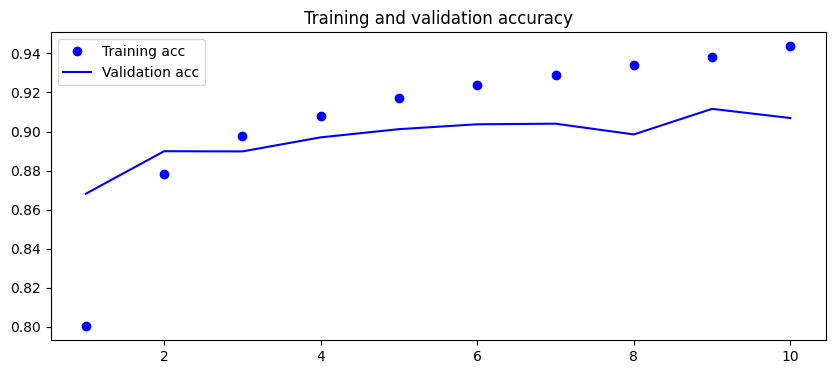

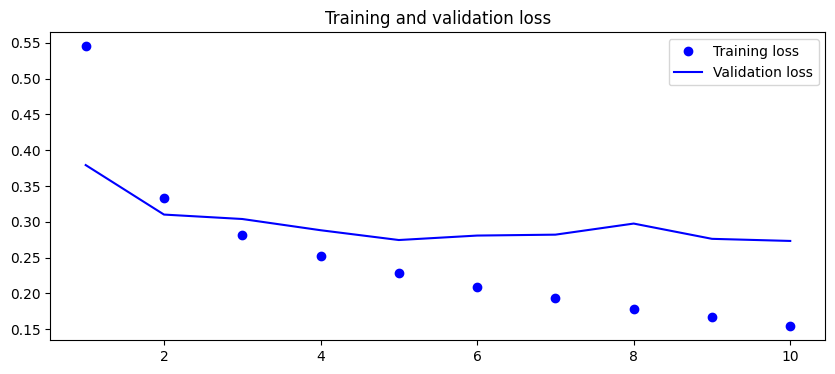

In [7]:
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = range(1, len(acc) + 1)

plt.figure(figsize=(10, 4))
plt.plot(epochs, acc, "bo", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("Training and validation accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(epochs, loss, "bo", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.legend()
plt.show()

In [8]:
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f"Точність базової CNN: {test_acc:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9069 - loss: 0.2732
Точність базової CNN: 0.9069


VGG16

In [9]:
import tensorflow as tf
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras import models, layers
import numpy as np

In [10]:
(train_images_raw, train_labels_raw), (test_images_raw, test_labels_raw) = fashion_mnist.load_data()

In [11]:
train_padded = np.pad(train_images_raw, ((0,0), (2,2), (2,2)), mode='constant')
test_padded = np.pad(test_images_raw, ((0,0), (2,2), (2,2)), mode='constant')

In [12]:
train_images_vgg = np.expand_dims(train_padded, axis=-1)
train_images_vgg = np.repeat(train_images_vgg, 3, axis=-1).astype("float32") / 255

test_images_vgg = np.expand_dims(test_padded, axis=-1)
test_images_vgg = np.repeat(test_images_vgg, 3, axis=-1).astype("float32") / 255

train_labels_vgg = to_categorical(train_labels_raw)
test_labels_vgg = to_categorical(test_labels_raw)

In [13]:
conv_base = VGG16(weights="imagenet", include_top=False, input_shape=(32, 32, 3))
conv_base.trainable = False

model_vgg = models.Sequential([
    conv_base,
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(256, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_vgg.compile(
    loss="categorical_crossentropy",
    optimizer=tf.keras.optimizers.RMSprop(learning_rate=2e-5),
    metrics=["accuracy"]
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [14]:
print("Навчання класифікатора (заморожена база)")
model_vgg.fit(
    train_images_vgg, train_labels_vgg,
    epochs=5,
    batch_size=64,
    validation_data=(test_images_vgg, test_labels_vgg)
)

Навчання класифікатора (заморожена база)
Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 18s 15ms/step - accuracy: 0.3453 - loss: 1.9349 - val_accuracy: 0.6625 - val_loss: 1.4046
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.6061 - loss: 1.2888 - val_accuracy: 0.7128 - val_loss: 0.9835
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.6702 - loss: 1.0255 - val_accuracy: 0.7328 - val_loss: 0.8292
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.6948 - loss: 0.9109 - val_accuracy: 0.7457 - val_loss: 0.7584
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.7068 - loss: 0.8519 - val_accuracy: 0.7554 - val_loss: 0.7173


In [15]:
conv_base.trainable = True

set_trainable = False
for layer in conv_base.layers:
    if layer.name == "block5_conv1":
        set_trainable = True
    if set_trainable:
        layer.trainable = True
    else:
        layer.trainable = False

In [16]:
model_vgg.compile(
    loss="categorical_crossentropy",
    optimizer=tf.keras.optimizers.RMSprop(learning_rate=1e-5),
    metrics=["accuracy"]
)

In [17]:
print("Донавчання (Fine-Tuning)")
history_vgg = model_vgg.fit(
    train_images_vgg, train_labels_vgg,
    epochs=10,
    batch_size=64,
    validation_data=(test_images_vgg, test_labels_vgg)
)

Донавчання (Fine-Tuning)
Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 22s 19ms/step - accuracy: 0.8162 - loss: 0.5069 - val_accuracy: 0.8607 - val_loss: 0.3839
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.8644 - loss: 0.3753 - val_accuracy: 0.8802 - val_loss: 0.3379
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.8796 - loss: 0.3346 - val_accuracy: 0.8832 - val_loss: 0.3255
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.8885 - loss: 0.3081 - val_accuracy: 0.8906 - val_loss: 0.3105
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.8955 - loss: 0.2890 - val_accuracy: 0.8931 - val_loss: 0.2999
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.8994 - loss: 0.2744 - val_accuracy: 0.8966 - val_loss: 0.2948
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.9051 - loss: 0.2612 - val_accuracy: 0.9009 - val_loss: 0.2778
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy:

In [18]:
test_loss_vgg, test_acc_vgg = model_vgg.evaluate(test_images_vgg, test_labels_vgg)
print(f"Точність VGG16 (Fine-Tuning): {test_acc_vgg:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9018 - loss: 0.2752
Точність VGG16 (Fine-Tuning): 0.9018
